In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import geopandas as gpd
import adjustText

In [ ]:
#On définit la police de caractères pour les graphiques
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans", "Arial"]

#On améliore la qualité des graphiques
%config InlineBackend.figure_format = 'retina'

In [ ]:
#Chargement du fond de carte de l'Île-de-France
gdf_iris = gpd.read_file("IDF_iris.geojson")
gdf_iris.head()

,typ_iris,insee_com,code_iris,nom_iris,dep,geo_point_2d,id,iris,nom_com,geometry
0,A,95051,950510105,Zone d'Activités,95,"[49.01802685248178, 2.1826610243984375]",IRIS____0000000950510105,0105,Beauchamp,"POLYGON ((2.18649 49.01053, 2.17345 49.01405, ..."
1,A,75112,751124811,Quinze-Vingts 11,75,"[48.844104305775815, 2.3753123018512237]",IRIS____0000000751124811,4811,Paris 12e Arrondissement,"POLYGON ((2.37114 48.84553, 2.37268 48.84568, ..."
2,D,75115,751156023,Jardin Citroën-Cévennes,75,"[48.840354178960965, 2.2752169001780462]",IRIS____0000000751156023,6023,Paris 15e Arrondissement,"POLYGON ((2.2746 48.84352, 2.27488 48.84342, 2..."
3,H,92062,920620101,Défense Nord,92,"[48.89129954997267, 2.23681617518544]",IRIS____0000000920620101,0101,Puteaux,"POLYGON ((2.24187 48.89066, 2.24236 48.8905, 2..."
4,H,92014,920140101,Les Bas Coquarts,92,"[48.78723129083917, 2.31362300907206]",IRIS____0000000920140101,0101,Bourg-la-Reine,"POLYGON ((2.31047 48.78489, 2.3097 48.7849, 2...."


In [ ]:
#Récupération du tracé de la Ligne 14 (site IDFM)
ligne_14 = gpd.read_file("/Users/borhane/Documents/2A ENSAE/Projet Python 2A/projet_python_2a_ensae/traces-des-lignes-de-transport-en-commun-idfm-2.geojson")
ligne_14.head()

#On sélectionne la zone d'étude correspondant à la commune de Saint-Ouen (code INSEE 93070)
col_insee = 'insee_com' if 'insee_com' in gdf_iris.columns else 'depcom'
zone_etude = gdf_iris[gdf_iris[col_insee].astype(str) == '93070'] #Je force ici à convertir en str pour éviter les problèmes de type de données (les codes iNSEE sont lus comme des int ce qui pose problème)

# Vérifier et convertir si nécessaire le système de coordonnées de la ligne 14 pour qu'il corresponde à celui de la zone d'étude
if ligne_14.crs != zone_etude.crs:
    ligne_14 = ligne_14.to_crs(zone_etude.crs)

In [ ]:
#On récupère les emplacements des stations de métro de la ligne 14 (site IDFM)
gdf_stations = gpd.read_file("/Users/borhane/Documents/2A ENSAE/Projet Python 2A/projet_python_2a_ensae/emplacement-des-gares-idf.geojson")

#On vérifie que le système de coordonnées des stations correspond à celui de la zone d'étude, sinon on le convertit
if gdf_stations.crs != zone_etude.crs:
    gdf_stations = gdf_stations.to_crs(zone_etude.crs)

#On sélectionne uniquement les stations de la 14 à Saint-Ouen
stations_st_ouen = gdf_stations.cx[
    minx - marge_x : maxx + marge_x, 
    miny - marge_y : maxy + marge_y] #.cx fait un slicing spaital qui permet de sélectionner les stations dans la zone d'étude (Saint-Ouen) en utilisant les limites géographiques calculées précédemment

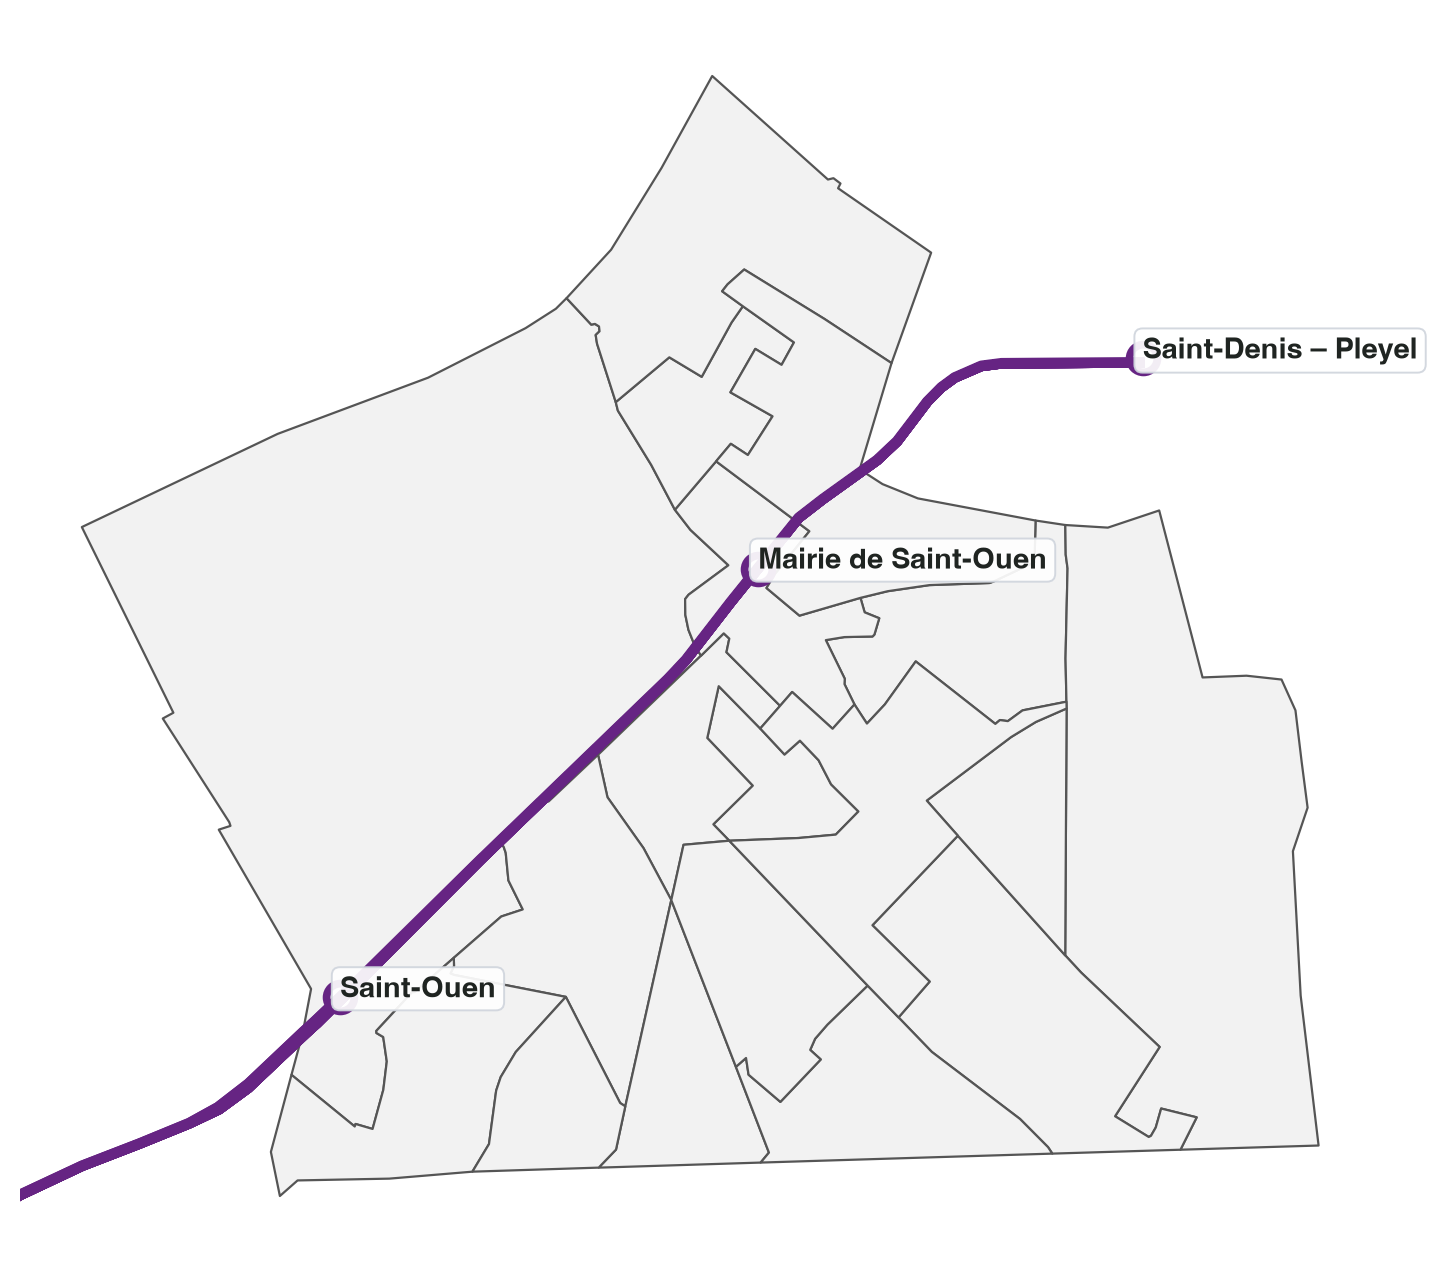

In [ ]:
# Visualisation de la zone d'étude et de la ligne 14
fig, ax = plt.subplots(figsize=(10, 8))

zone_etude.plot(
    ax=ax,
    color="#f2f2f2",
    edgecolor="#555555",
    linewidth=0.8,
    label="Quartiers (IRIS)"
)
ligne_14.plot(
    ax=ax,
    color="#662483",
    linewidth=3.5,
    zorder=4,
    label="Ligne 14",
)

stations_st_ouen.plot(
    ax=ax,
    color="white",
    edgecolor="#662483",
    linewidth=2.8,
    markersize=100,
    zorder=3,
    label="Stations de métro"
)

#On ajoute les noms des stations de métro sur la carte
texts = []
for _, row in stations_st_ouen.iterrows():
    pt = row.geometry
    t = ax.text(
        pt.x,
        pt.y,
        row["nom_zda"],
        fontsize=10.5,
        fontweight="semibold",
        color="#1f2421",
        zorder=6,
        bbox=dict(
            boxstyle="round,pad=0.28",
            facecolor="white",
            edgecolor="#d0d5dd",
            linewidth=0.7,
            alpha=0.92,
        ),
    )
    texts.append(t)

# Récupérer les limites géographiques (bords min et max) de Saint-Ouen
minx, miny, maxx, maxy = zone_etude.total_bounds #On récupère les limites géographiques de la zone d'étude (Saint-Ouen) pour ajuster le zoom du graphique (longitude et latitude)

# Ajouter une petite marge (ex: 10% autour) pour que les tracés ne touchent pas les bords du cadre
marge_x = (maxx - minx) * 0.05
marge_y = (maxy - miny) * 0.05

# Appliquer le zoom sur les axes du graphique
ax.set_xlim(minx - marge_x, maxx + marge_x)
ax.set_ylim(miny - marge_y, maxy + marge_y)

#On n'affiche pas les axes pour un rendu plus esthétique
ax.set_axis_off()

plt.show()

In [ ]:
#Etudier les revenus des ménages 

In [ ]:
# 1. Charger le fichier texte brut avec le séparateur '|'
df_2018 = pd.read_csv(
    "valeursfoncieres-2018.txt",
    sep="|",
    decimal=",",  # Convertit '8000,00' en nombre 8000.0
    dtype={"Code departement": str, "Code commune": str},
    low_memory=False,
)

# 2. Reconstituer le code INSEE à 5 chiffres ('93' + '070' = '93070')
df_2018["code_insee"] = (
    df_2018["Code departement"].astype(str).str.zfill(2)
    + df_2018["Code commune"].astype(str).str.zfill(3)
)

# 3. Filtrer uniquement sur Saint-Ouen (93070)
df_st_ouen_2018 = df_2018[df_2018["code_insee"] == "93070"].copy()

# 4. Convertir la date au format Datetime
df_st_ouen_2018["Date mutation"] = pd.to_datetime(
    df_st_ouen_2018["Date mutation"], format="%d/%m/%Y"
)

# 5. Ajouter une colonne pour l'année
df_st_ouen_2018["annee"] = 2018

print(f"Nombre de transactions à Saint-Ouen en 2018 : {len(df_st_ouen_2018)}")
df_st_ouen_2018.head()

Nombre de transactions à Saint-Ouen en 2018 : 2300


,Code service CH,Reference document,1 Articles CGI,2 Articles CGI,3 Articles CGI,4 Articles CGI,5 Articles CGI,No disposition,Date mutation,Nature mutation,...,Code type local,Type local,Identifiant local,Surface reelle bati,Nombre pieces principales,Nature culture,Nature culture speciale,Surface terrain,code_insee,annee
3087372,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2018-01-04,Vente en l'état futur d'achèvement,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93070,2018
3087373,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2018-01-04,Vente en l'état futur d'achèvement,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93070,2018
3087374,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2018-01-09,Vente en l'état futur d'achèvement,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93070,2018
3087375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2018-01-09,Vente en l'état futur d'achèvement,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93070,2018
3087376,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2018-01-09,Vente en l'état futur d'achèvement,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,93070,2018


In [9]:
# 1. Voir les types de transactions enregistrées
print(df_st_ouen_2018["Nature mutation"].value_counts(dropna=False))

# 2. Voir les types de locaux renseignés
print(df_st_ouen_2018["Type local"].value_counts(dropna=False))

Nature mutation
Vente                                 1561
Vente en l'état futur d'achèvement     711
Adjudication                            12
Expropriation                            9
Echange                                  7
Name: count, dtype: int64
Type local
Appartement                                 1032
NaN                                          448
Dépendance                                   442
Local industriel. commercial ou assimilé     346
Maison                                        32
Name: count, dtype: int64


Y'a beaucoup de ventes en l'état futur d'achèvement. 

On peut regarder une ville comparable qui a pas eu la 14 pour voir si c'est vrmt le métro qui a eu un effet et pas juste l'évolution naturelle du marché immobilier. Pour détrender on regarde ce qu'aurait été le marché à St Ouen avec un coef régional d'évolution du prix de l'immobilier, et comaprer à la réalité. 